# EDA de la línea base AS-IS (Objetivo Específico 1)

**Tesis:** Pipeline multiagente de IA para el ciclo de vida del requerimiento de software (UNI).
**Objetivo:** medir el estado actual del proceso (el *antes*) con los seis indicadores de las hipótesis H1–H6, a partir de los datos operativos de la Empresa (`data/linea_base/Linea_BaseV2.xlsx`: 6 proyectos, 150 requerimientos).

El análisis es **descriptivo**: produce la línea base (observación O1 del diseño cuasiexperimental). No prueba hipótesis; eso ocurre en el piloto (OE4).
**Determinismo:** no hay muestreo ni aleatoriedad; toda cifra sale de agregar columnas del Excel. Cualquier persona obtiene los mismos números.

| Fase | Contenido |
|---|---|
| 0 | Carga y validación de integridad |
| 1 | Distribuciones (justifica pruebas no paramétricas) |
| 2 | Descomposición del lead time en trabajo y espera |
| 3 | Los seis indicadores H1–H6 |
| 4 | Segmentación por proyecto y sub-línea base del piloto (SIM-P05) |

In [1]:
# En Colab: descarga el Excel desde el repositorio público
import os, urllib.request
ARCHIVO = "Linea_BaseV2.xlsx"
if not os.path.exists(ARCHIVO):
    urllib.request.urlretrieve("https://github.com/javierrosado/tesis/raw/main/data/linea_base/Linea_BaseV2.xlsx", ARCHIVO)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats

## Fase 0 · Carga y validación
En todas las hojas la primera fila está vacía y los encabezados están en la segunda (`header=1`).

In [2]:
proyectos      = pd.read_excel(ARCHIVO, "Proyectos", header=1)
requerimientos = pd.read_excel(ARCHIVO, "Requerimientos", header=1)
defectos       = pd.read_excel(ARCHIVO, "Defectos", header=1)
despliegues    = pd.read_excel(ARCHIVO, "Despliegues", header=1)
handoffs       = pd.read_excel(ARCHIVO, "Handoffs", header=1)
proyectos = proyectos[proyectos["proyecto_id"].astype(str).str.startswith("SIM-P")].copy()   # sin fila de totales

lt = (pd.to_datetime(requerimientos["fecha_produccion"]) - pd.to_datetime(requerimientos["fecha_registro"])).dt.days
validaciones = pd.DataFrame({
    "comprobación": ["Filas Proyectos / Requerimientos / Defectos / Despliegues / Handoffs",
                     "Toda clave proyecto_id de Requerimientos existe en Proyectos",
                     "Lead time recalculado desde fechas = columna lead_time_d",
                     "Suma de n_defectos = filas de la hoja Defectos"],
    "resultado": [f"{len(proyectos)} / {len(requerimientos)} / {len(defectos)} / {len(despliegues)} / {len(handoffs)}",
                  str(requerimientos["proyecto_id"].isin(proyectos["proyecto_id"]).all()),
                  f"{(lt == requerimientos['lead_time_d']).sum()} de {len(requerimientos)}",
                  f"{int(requerimientos['n_defectos'].sum())} = {len(defectos)}"]})
validaciones

,comprobación,resultado
0,Filas Proyectos / Requerimientos / Defectos / ...,6 / 150 / 83 / 40 / 666
1,Toda clave proyecto_id de Requerimientos exist...,True
2,Lead time recalculado desde fechas = columna l...,150 de 150
3,Suma de n_defectos = filas de la hoja Defectos,83 = 83


**Lectura:** los datos son íntegros; se puede calcular sobre las columnas existentes.

## Fase 1 · Distribuciones

count    150.0
mean      69.7
std       24.8
min       29.0
25%       50.2
50%       66.5
75%       83.0
90%      100.0
max      149.0

Shapiro-Wilk: W = 0.947, p = 0.0000 → no normal


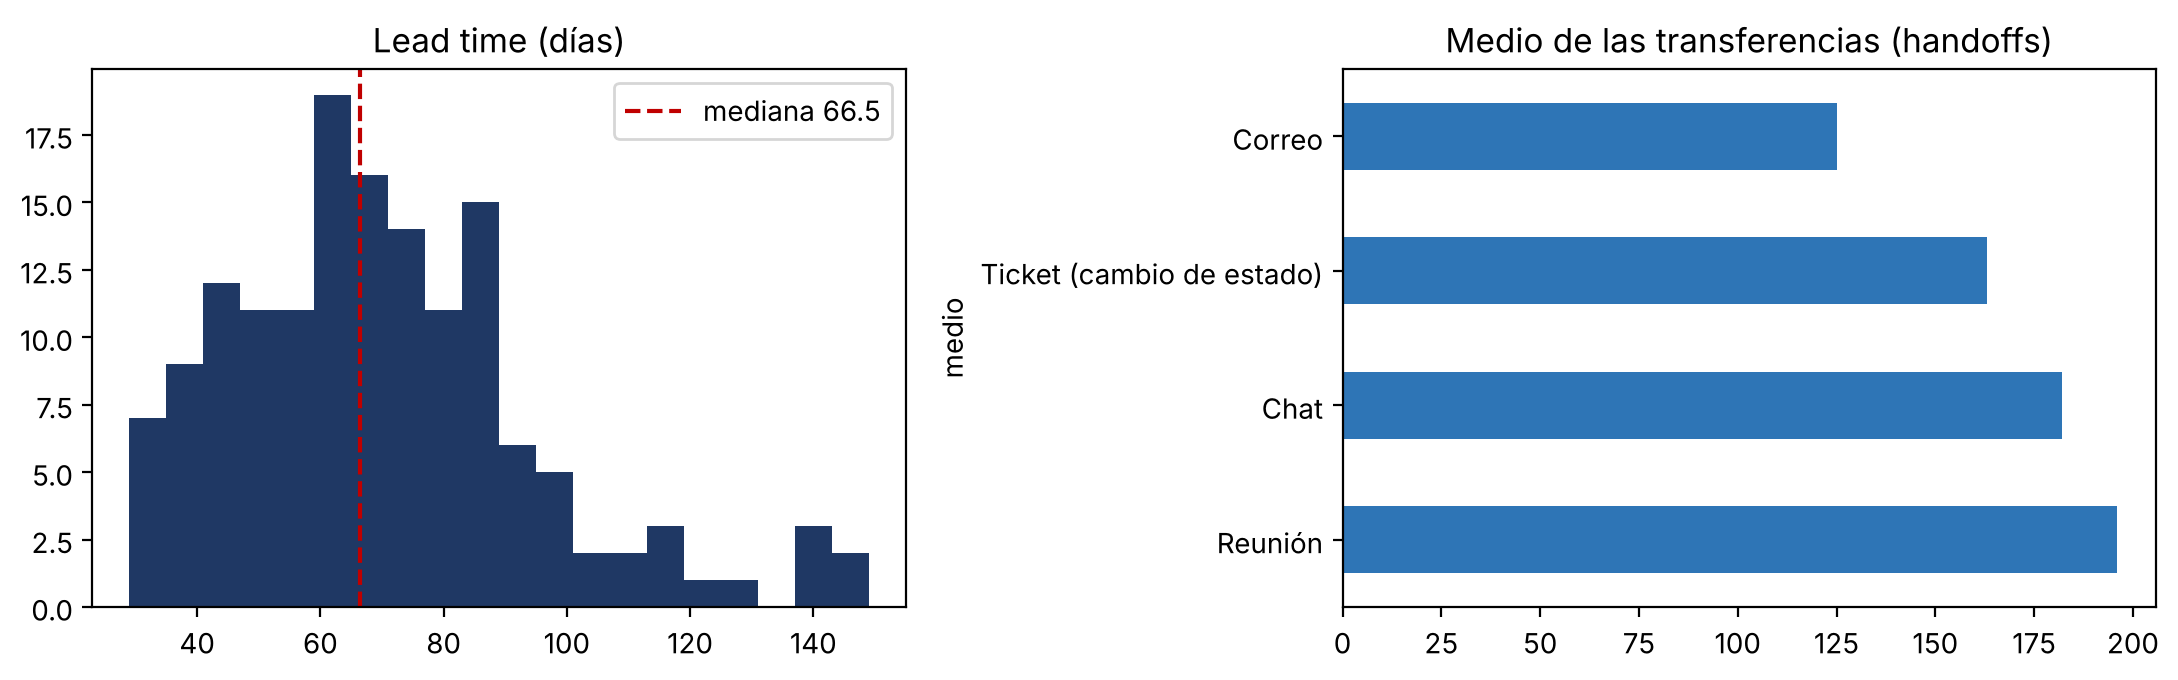

In [3]:
ltd = requerimientos["lead_time_d"]
print(ltd.describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
w = stats.shapiro(ltd); print(f"\nShapiro-Wilk: W = {w.statistic:.3f}, p = {w.pvalue:.4f} → {'no normal' if w.pvalue < 0.05 else 'normal'}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(ltd, bins=20, color="#1F3864"); ax[0].axvline(ltd.median(), color="#C00000", ls="--", label=f"mediana {ltd.median()}"); ax[0].set_title("Lead time (días)"); ax[0].legend()
handoffs["medio"].value_counts().plot.barh(ax=ax[1], color="#2E75B6"); ax[1].set_title("Medio de las transferencias (handoffs)")
plt.tight_layout(); plt.show()

**Lectura:** el lead time está sesgado a la derecha y no es normal; por eso se usa la mediana y pruebas no paramétricas (Mann-Whitney, Wilcoxon, Fisher) para contrastar con el piloto.

## Fase 2 · Descomposición del lead time

Proporción de espera en el lead time: 69.1%


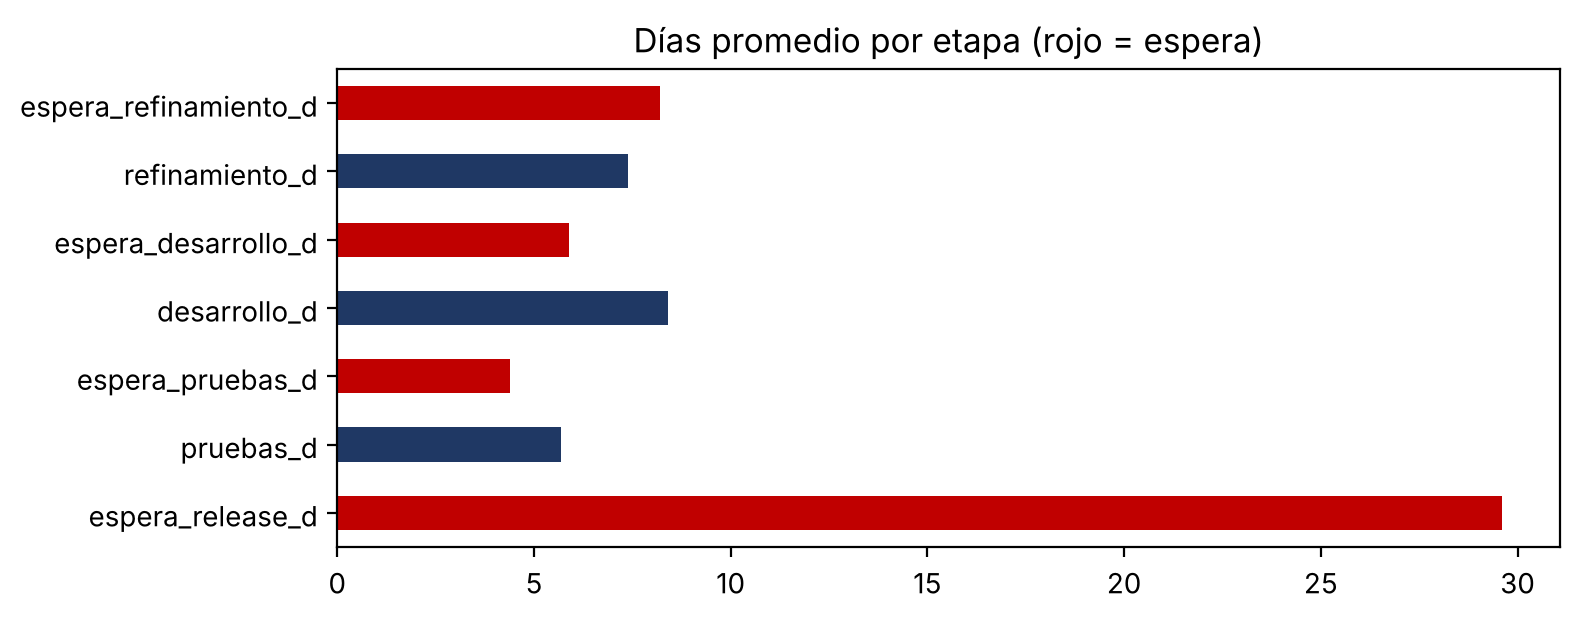

In [4]:
espera  = ["espera_refinamiento_d", "espera_desarrollo_d", "espera_pruebas_d", "espera_release_d"]
trabajo = ["refinamiento_d", "desarrollo_d", "pruebas_d"]
orden = ["espera_refinamiento_d", "refinamiento_d", "espera_desarrollo_d", "desarrollo_d", "espera_pruebas_d", "pruebas_d", "espera_release_d"]
medias = requerimientos[orden].mean().round(1)
prop_espera = requerimientos[espera].sum().sum() / requerimientos[espera + trabajo].sum().sum()
print(f"Proporción de espera en el lead time: {prop_espera:.1%}")
medias.plot.barh(color=["#C00000" if k in espera else "#1F3864" for k in orden], figsize=(8, 3.2), title="Días promedio por etapa (rojo = espera)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

**Lectura:** casi el 70 % del lead time es espera y la mayor es la espera antes del release: el proceso es lento por tiempos muertos entre etapas, no por falta de trabajo.

## Fase 3 · Los seis indicadores (H1–H6)

In [5]:
meses = proyectos.set_index("proyecto_id")["meses_activos"]
falla = despliegues["resultado"].astype(str).str.lower().eq("fallido")
si = lambda s: s.astype(str).str.strip().str.lower().isin(["sí", "si", "1", "true"])
ind = pd.DataFrame([
  ["H1 Velocidad", "Lead time mediano (días)", ltd.median(), "≤ 7"],
  ["H2 Estabilidad", "Despliegues fallidos / total", f"{falla.mean():.1%} ({falla.sum()}/{len(despliegues)})", "≤ 15 %"],
  ["H3 Calidad", "Requerimientos con defecto / total", f"{requerimientos['con_defecto'].mean():.1%} ({int(requerimientos['con_defecto'].sum())}/{len(requerimientos)})", "≤ 17 %"],
  ["H4 Agilidad", "Despliegues por mes y proyecto (todos)", round(despliegues.groupby("proyecto_id").size().div(meses).mean(), 2), "≥ 1,5"],
  ["H5 Gobernanza", "Trazabilidad completa", f"{si(requerimientos['trazabilidad_completa']).mean():.1%}", "100 %"],
  ["H6 Coordinación", "Handoffs automáticos · registrados", f"{si(handoffs['automatico']).mean():.1%} · {si(handoffs['registrado_formalmente']).mean():.1%}", "≥ 90 % · 100 %"],
], columns=["Hipótesis", "Indicador", "Línea base", "Meta del piloto"])
ind

,Hipótesis,Indicador,Línea base,Meta del piloto
0,H1 Velocidad,Lead time mediano (días),66.5,≤ 7
1,H2 Estabilidad,Despliegues fallidos / total,45.0% (18/40),≤ 15 %
2,H3 Calidad,Requerimientos con defecto / total,34.0% (51/150),≤ 17 %
3,H4 Agilidad,Despliegues por mes y proyecto (todos),1.02,"≥ 1,5"
4,H5 Gobernanza,Trazabilidad completa,0.0%,100 %
5,H6 Coordinación,Handoffs automáticos · registrados,0.0% · 30.9%,≥ 90 % · 100 %


In [6]:
# Indicadores de apoyo
print("Fuga a producción (defectos detectados en producción):", f"{defectos['fase_deteccion'].astype(str).str.lower().str.contains('producci').mean():.1%}")
print("Severidad de defectos:", defectos["severidad"].value_counts().to_dict())
print("H4 contando solo releases en ventana:", round(despliegues[despliegues['tipo'].astype(str).str.lower().str.contains('release')].groupby('proyecto_id').size().div(meses).mean(), 2))

Fuga a producción (defectos detectados en producción): 42.2%
Severidad de defectos: {'Media': 27, 'Alta': 27, 'Baja': 19, 'Crítica': 10}
H4 contando solo releases en ventana: 0.69


**Lectura:** cinco indicadores reproducen exactamente los valores del plan (66,5 días; 45 %; 34 %; 0 %; 0 % / 30,9 %). H4 da 1,0 solo si se cuentan todos los despliegues (releases + hotfix); con solo releases baja a 0,69. Es la única decisión metodológica explícita de la línea base.

## Fase 4 · Por proyecto y sub-línea base del piloto (Squad Fuerza de Ventas, SIM-P05)

In [7]:
por_proy = pd.DataFrame({
  "requerimientos": requerimientos.groupby("proyecto_id").size(),
  "lead time mediano": requerimientos.groupby("proyecto_id")["lead_time_d"].median(),
  "tasa de fallos": despliegues.assign(f=falla).groupby("proyecto_id")["f"].mean().round(3),
  "con defecto": requerimientos.groupby("proyecto_id")["con_defecto"].mean().round(3)})
por_proy

,requerimientos,lead time mediano,tasa de fallos,con defecto
proyecto_id,,,,
SIM-P01,26,62.5,0.333,0.385
SIM-P02,24,63.5,0.143,0.250
SIM-P03,25,69.0,0.556,0.360
SIM-P04,23,74.0,0.500,0.261
SIM-P05,27,69.0,0.429,0.296
SIM-P06,25,70.0,0.714,0.480


In [8]:
p5 = lambda d: d[d["proyecto_id"] == "SIM-P05"]
f5 = p5(despliegues)["resultado"].astype(str).str.lower().eq("fallido")
pd.Series({"requerimientos": len(p5(requerimientos)), "lead time mediano (días)": p5(requerimientos)["lead_time_d"].median(),
           "tasa de fallos": f"{f5.mean():.1%} ({f5.sum()}/{len(f5)})", "con defecto": f"{p5(requerimientos)['con_defecto'].mean():.1%}",
           "handoffs registrados": f"{si(p5(handoffs)['registrado_formalmente']).mean():.1%} (de {len(p5(handoffs))})"}, name="SIM-P05 (piloto)")

requerimientos                          27
lead time mediano (días)              69.0
tasa de fallos                 42.9% (3/7)
con defecto                          29.6%
handoffs registrados        26.3% (de 118)
Name: SIM-P05 (piloto), dtype: object

## Conclusión

La línea base queda medida y verificada: lead time mediano de 66,5 días con 69 % de espera, 45 % de despliegues fallidos, 34 % de requerimientos con defecto, 0 % de trazabilidad completa y 0 % de handoffs automáticos (30,9 % registrados). Estos son los valores contra los que se contrastarán los resultados del piloto (OE4).